## Haplotype reconstruction to investigate SNV haplotype dynamics 
Reconstruction haplotypes for all TRANSIENT and FIXED snv with frequency above 5% :
- Complete genome/segments
- Non-synonymous SNVs per protein 

per passage (per line and per segment): reconstructing haplotpyes for SNVs that have a frequency 5% in that passage

## 0. General 

### 0.1. Load libraries

In [1]:
import os, pandas as pd, numpy as np, random
from Bio import SeqIO
from scipy.special import betaln
from scipy.optimize import minimize_scalar

In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.gridspec as gridspec

import seaborn as sns

sns.set_theme(style="white", font="Arial")
sns.set_context({'font.size': 10.0, 'axes.labelsize': 12, 'axes.titlesize': 14,
                 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
                 'legend.title_fontsize': None, 'axes.linewidth': 0.8, 'grid.linewidth': 0.8,
                 'lines.linewidth': 1.5, 'lines.markersize': 6.0, 'patch.linewidth': 1.0,
                 'xtick.major.width': 0.5, 'ytick.major.width': 0.5, 'xtick.minor.width': 0.3,
                 'ytick.minor.width': 0.3, 'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
                 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,})

plt.rcParams['xtick.bottom'] = True
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['font.size'] = 12
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True


### 0.2 General variables

In [3]:
haplotype_frequency_cutoff = 0.05

In [4]:
donors = [1,2,3,4]
replicates = ["A", "B", "C"]
passages = list(range(0, 110, 10))
tech_reps = [1,2 ]
populations = ["1A", "1B", "1C", "2A", "2B", "2C", "3A", "3B", "3C", "4A", "4B", "4C"]
segments = ["1-PB2", "2-PB1", "3-PA", "4-HA", "5-NP", "6-NA", "7-M", "8-NS"]

hours_per_passage = 72 #hours
generation_time = 6 #hours > assumption based on Baccam, et al. 2006

In [5]:
segment_nuc_cds = {r.id:r.seq for r in SeqIO.parse('../data/references/stock_consensus_cds.fasta', 'fasta')}


### 0.3. Functions 


In [6]:
def negative_log_likelihood_overdispersion(phi, y1, n1, y2, n2, p):
    theta = (1 - phi) / phi
    a = p * theta
    b = (1 - p) * theta
    ll = 0
    for y, n in [(y1, n1), (y2, n2)]:
        ll += (betaln(y + a, n - y + b) - betaln(a, b))
        
    return -ll.sum()

the function to generate the muller plot work. [How exactly? I don't know](https://i.redd.it/rskneik2r4h41.jpg). But I do know that *'if it ain't broke, don't fix it'*



In [7]:
def get_haplotypes(refname, haplotype_dir, sample, technical_rep, refseq, freq_cutoff=None):
    
    #get snv file used for haplotype 
    snv_df = pd.read_csv(os.path.join(haplotype_dir, "input", f"snvs_{sample}_{technical_rep}.csv"))
    #ensure poistions are sorted
    snv_df = snv_df[snv_df["refname"]==refname].set_index(['nucpos', 'read_base']).sort_index() 
    #if freq cutoff is specified remove SNVs below frequency cutoff 
    if freq_cutoff is not None:
        snv_df = snv_df[snv_df["nuc_freq"]>=freq_cutoff]
    
    #get reconstruct state file 
    all_states  = pd.read_csv(os.path.join(haplotype_dir, "reconstruction", sample, f"reconstructed_states_{sample}_{technical_rep}_{refname}.csv"))
    
    #get best haplotype results
    best_BIC = min(all_states['best BIC'])
    best_all_states_df = all_states[all_states['best BIC']==best_BIC]
    best_state = best_all_states_df.loc[best_all_states_df['LL'].idxmax()]
    best_freq = [float(v) for v in best_state["freq"].lstrip("[").rstrip("]").split(" ") if v != ""]
    best_haploset = eval(best_state['haplo set'])
    best_X_haplotype = best_state['X']
    best_LL = best_state['LL']

    #safety check
    if len(best_haploset[0]) !=  len(snv_df):
        print (f"haplotype length does not match the number of snvs for {sample} {technical_rep} {refname}")
        return [], []
    
    #another safety check 
    for nucpos in snv_df.index.get_level_values(0).unique():
        if len(snv_df.loc[[nucpos], :]) > 1:
            print (f"more than one snv found at nucpos {nucpos} for {sample} {technical_rep} {refname}" )
            return [], []
        
    #get haplotype frequency from freq dist file
    freq_dist = pd.read_csv(os.path.join(haplotype_dir, "reconstruction", sample, f"freq_dist_{sample}_{technical_rep}_{refname}.csv"), header=None)
    #taking mean haplotyp frequencies
    mean_freqs = [np.mean(freq_dist[c]) for c in freq_dist.columns]
        
    observed_haplotypes, observed_haplotype_frequencies = [], []
    for j, haploset in enumerate(best_haploset):
        snvs_in_haploset = []
        for i, base in enumerate(haploset):
            nucpos = snv_df.index.get_level_values(0).to_list()[i]
            if (nucpos, base) in snv_df.index.tolist():
                snvs_in_haploset.append(f"{refseq[nucpos-1]}{nucpos}{base}")
        observed_haplotypes.append(tuple(snvs_in_haploset))
        observed_haplotype_frequencies.append(mean_freqs[j])
    
    return observed_haplotypes, observed_haplotype_frequencies  

def generate_haplotype_df(population, refname, raw_haplotypes, detection_limit=None):
    haplotype_df = raw_haplotypes[(raw_haplotypes["population"]==population)&(raw_haplotypes["refname"]==refname)]
    haplotype_df = haplotype_df.pivot(columns="passage", index="haplotype", values="frequency")
    if detection_limit is not None:
        #removing haplotypes that never exceed the detection limit
        keep = [hid for hid, row in haplotype_df.iterrows() if len([v for v in row.values if v >= detection_limit])>0]
        haplotype_df = haplotype_df[haplotype_df.index.isin(keep)]
    return haplotype_df

def get_haplotype_order(haplotype_df, timepoints):
    haplotype_order = [tuple()]
    previous_haplotypes = [tuple()] 
    ancestry_tracker = {}
    for pi, passage in enumerate(timepoints[1:], start=1):
        previous_passage = timepoints[pi-1]
        if passage not in haplotype_df.columns:
            previous_haplotypes = [tuple()]
            continue
            
        #find all current haplotypes 
        current_haplotypes = haplotype_df[haplotype_df[passage]>0].index.tolist()
        #seperate haplotype already in haplotype df from those first observed this time 
        seen_haplotypes = [haplotype for haplotype in current_haplotypes if haplotype in previous_haplotypes or haplotype==tuple()]
        seen_haplotypes.sort(key=lambda s: len(s))
        new_haplotypes =[haplotype for haplotype in current_haplotypes if haplotype not in previous_haplotypes and haplotype!=tuple()]
        new_haplotypes.sort(key=lambda s: len(s))
    
        #start with new haplotyes
        for hi, haplotype in enumerate(new_haplotypes):
            loss = False
            ancestral_haplotypes = [haplotype] #haplotype ancestry from haplotype back to wt
            if haplotype in haplotype_order:
                continue
            
            #determine potential parent haplos
            potential_parent_haplotypes = [ph for ph in previous_haplotypes if \
            set(haplotype).issubset(ph) or set(ph).issubset(haplotype) and len(ph)>0 and ph!=haplotype]
            #current haplotype gained and snv relative to potential parents
            gain_parents = [ph for ph in potential_parent_haplotypes if set(ph).issubset(haplotype) ]
            #current haplotype lost an snv relative to potential parents
            loss_parents = [ph for ph in potential_parent_haplotypes if set(haplotype).issubset(ph)]
            
            #find parent 
            if len(potential_parent_haplotypes) == 0:
                #only possible parent is wild_type
                parent = tuple()
                ancestral_haplotypes.append(parent)
            elif len(potential_parent_haplotypes) ==1:
                if len(gain_parents) == 1: #haplotype has gained an SNV
                    parent = gain_parents[0]
                    ancestral_haplotypes.append(parent)

                else:#haplotype has lost on SNV
                    parent = loss_parents[0]
                    ancestral_haplotypes.append(parent)
                    
            else:
                if len(gain_parents) > 0 and len(loss_parents) > 0:
                    #here i'm simply going to go with the ancestor with the highest previous frequency
                    parent = haplotype_df[haplotype_df.index.isin(potential_parent_haplotypes)]
                    parent = parent[parent[previous_passage]==max(parent[previous_passage].tolist())].index.values[0]
                    ancestral_haplotypes.append(parent)
                    
                elif len(gain_parents) > 0:#haplotype results from an SNV gain
                    #see the longest possible parent 
                    #assuming that the longer (the more matching snvs) the parent the more probable is in ancestral to the haplotype 
                    for l in reversed(range(len(haplotype))):
                        possible_parents = [ph for ph in gain_parents if len(ph)==l]
                        if len(possible_parents) == 0: 
                            continue
                        
                        #only one possible parent
                        if len(possible_parents) == 1:
                            parent = possible_parents[0]
                            ancestral_haplotypes.append(parent)
                            
                            break
                        else: #else multiple parents 
                            #assuming haplotype is descendant from parent with the highest haplotype freq
                            parent = haplotype_df.loc[possible_parents]
                            parent = parent[parent[previous_passage]==parent[previous_passage].max()].index.tolist()[0]
                            ancestral_haplotypes.append(parent)
                            break
                
                else: #haplotype results from a loss in snv 
                    #see the shortest possible parent 
                    #assuming that the longer (the more matching snvs) the parent the more probable is in ancestral to the haplotype 
                    for l in  range(len(haplotype)+1):
                        possible_parents = [ph for ph in potential_parent_haplotypes if len(ph)==l]
                        if len(possible_parents) == 0: 
                            continue
                    
                        #only one possible parent
                        if len(possible_parents) == 1:
                            parent = possible_parents[0]
                            ancestral_haplotypes.append(parent)
                            break

                        else:
                            #assuming haplotype is descendant from parent with the highest haplotype freq
                            parent = haplotype_df.loc[possible_parents]
                            parent = parent[parent[previous_passage]==parent[previous_passage].max()].index.tolist()[0]
                            ancestral_haplotypes.append(parent)
                            break

            #find ancestry  
            if parent in ancestry_tracker.keys():
                ancestral_haplotypes.extend(ancestry_tracker[parent])
            #see if ancestral line goes back to wild type 
            while ancestral_haplotypes[-1] != tuple():
                latest_ancestor = ancestral_haplotypes[-1]
                ancestral_haplotypes.extend(ancestry_tracker[latest_ancestor])
            ancestry_tracker[haplotype] = ancestral_haplotypes[1:]
            
            #insert haplotype correctly in haplotype order
            #need to insert haplotype after latest parent observation 
            parent_idx = [i for i, h in enumerate(haplotype_order) if h == parent][-1]

            
            if len (haplotype_order[parent_idx+1:]) >0:
                to_extend = []
                for h in ancestral_haplotypes:
                    if h == haplotype_order[parent_idx+1:][0]:
                        break
                    to_extend.append(h)
                
            else:
                to_extend = ancestral_haplotypes
                
            
            haplotype_order = haplotype_order[:parent_idx+1] + to_extend + haplotype_order[parent_idx+1:]
            
            

        previous_haplotypes = current_haplotypes


  
    return haplotype_order

def generate_haplotype_plotting_df(haplotype_df, timepoints, haplotype_order, detection_limit=None):
    haplotype_plotdf = []
    for pi, passage in enumerate(timepoints, start=1):
        passage_row = [0.] * len(haplotype_order)
        if passage not in haplotype_df.columns:
            #get number of wt columns
            haplotype = tuple()
            haplotype_idx =[i for i, h in enumerate(haplotype_order) if h == haplotype]
            freq = 1.
            for i in haplotype_idx:
                passage_row[i] = freq/len(haplotype_idx)
                
        else:
            nonzero_haplotypes = haplotype_df[haplotype_df[passage]>0].index.tolist()
            for haplotype in nonzero_haplotypes:
                haplotype_idx =[i for i, h in enumerate(haplotype_order) if h == haplotype]
                freq = haplotype_df.loc[[haplotype], passage].values[0]
                for i in haplotype_idx:
                    passage_row[i] = freq/len(haplotype_idx)
        
        haplotype_plotdf.append([passage]+ passage_row)
    #initialize df
    haplotype_plotdf = pd.DataFrame.from_records(haplotype_plotdf, columns=["passage"]+haplotype_order).set_index("passage")
    haplotype_plotdf.columns.name = "haplotype"
    haplotype_plotdf 
    
    if detection_limit is None:
        return haplotype_plotdf
    
    else:
        #iterate over observation below detection limit 
        for haplotype, row in haplotype_df.iterrows():
            if haplotype == tuple():
                continue
            for passage in haplotype_df.columns:
                if row[passage] < detection_limit:
                    #add frequency to parent
                    parent_idx = [i-1 for i, h in enumerate(haplotype_order) if h == haplotype]
                    for pi in parent_idx:
                        if haplotype_plotdf.iloc[timepoints.index(passage), pi] >0:
                            haplotype_plotdf.iloc[timepoints.index(passage), pi] += row[passage]/len(parent_idx)
                    
                    haplo_idx = [i for i, h in enumerate(haplotype_order) if h == haplotype]
                    for hi in haplo_idx:
                        haplotype_plotdf.iloc[timepoints.index(passage), hi] =0.
        
        #for cleaness of figure check > if total frequency sum to 1 
        #if not add remaining frequency according to proportion
        for i, passage in enumerate(timepoints):
            freq_sum = round(haplotype_plotdf.loc[passage].sum(),5)
            if freq_sum <1:
                remaining_freq = 1 - freq_sum
                for j, freq in enumerate(haplotype_plotdf.loc[passage].values):
                    if freq > 0:
                        new_freq = freq + ((freq/freq_sum)*remaining_freq)
                        haplotype_plotdf.iloc[i,j] = new_freq
           
    return haplotype_plotdf

def generate_color_per_haplotype(haplotype_order, haplotype_appearance=None, seed=None, non_synonymous_dict=None): 
    
    #coloring random
    if non_synonymous_dict is None:
        color_list = ['#A3CCC9','#02ABBD','#4A7FA0','#524FA1','#3132B7','#0978DC','#18825F','#489E10','#BBC735','#DDB40C','#F76C20',
                    '#ED4626','#DB2719','#B30219','#D0339C','#C42BD5','#912DD2',]

        # cmap = plt.colormaps['plasma']
        # color_list = [mpl.colors.to_hex(c) for c in cmap(np.linspace(0, 1, len(haplotype_appearance)))]
        if seed is not None:
            random.seed(seed)
            random.shuffle(color_list) 
    #coloring random but indicating last gain i.e. synonymous non synonymous
    else:
        color_list_nonsyn = [ "#693668", "#bd2d87", "#c52184", "#a30015", "#a74482", "#d664be", "#e574bc", "#f9b4ed", "#df99f0", "#f84aa7", "#ff3562", "#ff33cc" ]
        color_list_nonsyn = [ "#fa9fb5", "#f768a1", "#dd3497", "#ae017e", "#7a0177" ]
        color_list_syn = [ "#31572c", "#216869", "#235726", "#4f772d", "#53a548", "#4ccc55", "#00a66c", "#91cb3e", "#9cc5a1", "#90a955", "#abc72e"]
        color_list_syn = [ "#137547", "#2d6a4f", "#718355", "#007f5f", "#3fa34d", "#55a630", "#80b918", "#5bba6f", "#aacc00", "#bfd200", "#97a97c", "#b5c99a" ]
        if seed is not None:
            random.seed(seed)
            random.shuffle(color_list_nonsyn)
            random.shuffle(color_list_syn) 
            
    #if haplotype appearance is not specified infering from haplotype order
    if haplotype_appearance is None:
        haplotype_appearance = []
        for haplo in haplotype_order:
            if haplo!=tuple() and haplo not in haplotype_appearance:
                haplotype_appearance.append(haplo)
       
    if non_synonymous_dict is None:
        col_order = []
        for haplo in haplotype_order:
            if haplo == tuple():
                #col_order.append("#FFFFFF")
                col_order.append("#DDDDDD")
                
            else:
                i = haplotype_appearance.index(haplo)
                while i >= len(color_list):
                    i = i - len(color_list)
                
                col_order.append(color_list[i])
                
    else:
        col_order = []
        syn_c, ns_c = -1, -1
        for i, haplo in enumerate(haplotype_order):
            
            if haplo == tuple():
                #col_order.append("#FFFFFF")
                col_order.append("#DDDDDD")
                
            elif len(haplo) == 1:
                #if seen before
                if haplo in haplotype_order[:i-1]:
                    col_order.append(col_order[haplotype_order[:i-1].index(haplo)])
                
                elif haplo[0] in non_synonymous_dict:
                    ns_c += 1
                    if ns_c == len(color_list_nonsyn):
                        ns_c = 0
                    col_order.append(color_list_nonsyn[ns_c])
                else:
                    syn_c+= 1
                    if syn_c == len(color_list_syn):
                        syn_c = 0
                    col_order.append(color_list_syn[syn_c])
            else:
                if haplo in haplotype_order[:i-1]:
                    col_order.append(col_order[haplotype_order[:i-1].index(haplo)])
                else:
                    prev_haplo = haplotype_order[i-1]
                    
                    if len(prev_haplo) < len(haplo):
                        new_snv = tuple(set(haplo) - set(prev_haplo))[0]
                        if new_snv in non_synonymous_dict:
                            ns_c+=1 
                            if ns_c == len(color_list_nonsyn):
                                ns_c = 0
                            col_order.append(color_list_nonsyn[ns_c])
                        else:
                            syn_c += 1
                            if syn_c == len(color_list_syn):
                                syn_c = 0
                            col_order.append(color_list_syn[syn_c])
                    else:
                        
                        print ("loss I have not encountered this yet and need to write code for it ")

    return col_order  

def get_haplotype_appearance(haplotype_df):
    appearance_order = []
    for c in haplotype_df.columns:
        nonzero_haplotypes = [i for i, row in haplotype_df.sort_values(c, ascending=False).iterrows() if not pd.isna(row[c]) ]
        for haplotype in nonzero_haplotypes:
            if haplotype == tuple():
                continue
            if haplotype not in appearance_order:
                appearance_order.append(haplotype)
                
    return appearance_order

def draw_non_vertical_edges(collection, color='black', linewidth=1):
    
    ax = collection.axes #get ax from collection
    for path in collection.get_paths(): #go every polygon in the stackplot
        vertices = path.vertices
    
        if vertices.shape[0] < 2:
            continue
            
        num_sides = len(vertices) #get sides
        
        for i in range(num_sides):
            x1, y1 = vertices[i]
            
            
            if i < num_sides - 1: #skipping last 
                x2, y2 = vertices[i+1]
            else:
                continue 
            
            #find non-vertical edges
            if x1 != x2:
                line = Line2D([x1, x2], [y1, y2], color=color, linewidth=linewidth, linestyle='-',zorder=collection.get_zorder() + 1)
                ax.add_line(line)

def muller_plot(ax, timepoints, haplotype_plotdf, haplotype_order, haplotype_appearance=None, alpha=0.4, edgecolor="white", custom_color_list=None, color_seed=None, non_synonymous_dict=None):
    
    if custom_color_list is None:
        colors_plot = generate_color_per_haplotype(haplotype_order,haplotype_appearance, seed=color_seed, non_synonymous_dict=non_synonymous_dict)
    else:
        colors_plot =custom_color_list
    
    p = ax.stackplot(timepoints, haplotype_plotdf.values,edgecolors="none",
    linewidth=1, colors=colors_plot, alpha=alpha,)
    # #keep having weird horizonal lines no matter what i do, so creatively filling those up
    
    #spliting figure in passage chunks 
    for p, nextp in zip(timepoints[:-1], timepoints[1:]):
        df = haplotype_plotdf[[p, nextp]].reset_index()
        drop = [i for i, row in df.iterrows() if row[p]==0 and row[nextp]==0]
        df = df[~df.index.isin(drop)].set_index("haplotype")
        
        #see what haplotype Id levels can be merged
        ci = -1
        ndf = []
        for i, hid in enumerate(df.index):
            if i <= ci:
                continue
            li = i
            for j, nhid in enumerate(df.index[i+1:], start=i+1):
                if nhid != hid:
                    break
                else:
                    li = j
                    
            ndf.append([hid] + df.iloc[i:li+1, :].sum().values.tolist())
            ci= li
        ndf = pd.DataFrame.from_records(ndf, columns=["haplotype", p, nextp]).set_index("haplotype")
        
        #get colors for current level
        color_by_position = dict(zip(range(len(haplotype_order)), colors_plot))
        haplotype_to_indices = {}
        for idx, h in enumerate(haplotype_order):
            haplotype_to_indices.setdefault(h, []).append(idx)

        color_list = [color_by_position[haplotype_to_indices[hid][0]] for hid in ndf.index.tolist()]


        plot = ax.stackplot([p, nextp],ndf.values,edgecolors='none',
                        linewidth=1, colors=color_list, alpha=alpha, zorder=10)
    
        for collection in plot:
            draw_non_vertical_edges(collection, color=edgecolor, linewidth=0.5) 


    return p  

def muller_plot_cosmetics(ax, timepoints, ylabel=False, ylabelsize=8):
    ax.set_xlim(-0, timepoints[-1])
    ax.spines[['top','right']].set_visible(False)
    ax.set_ylim(0,1)
    ax.set_yticklabels([])
    ax.axvline(0, color="black", zorder=100, lw=0.5)
    if ylabel: 
        ax.set_ylabel("relativeabundance")

def annotate_muller_plot( ax,haplotype_df,haplotype_plotdf, non_synonymous_dict, color_dict, textsize=8):
    
    texts = []
    for haplotype, row in haplotype_df.iterrows():
        plotdf_idx = [i for i, c in enumerate(haplotype_plotdf.columns) if c == haplotype]
        
        if haplotype == tuple():

            continue  # skip wildtype

        tf = 0.1 if row.dropna().max() > 0.1 else 0.05 if row.dropna().max() > 0.05 else row.dropna().max()
        x = [p for p, f in row.dropna().items() if f >= tf][0]
        
        pi = haplotype_plotdf.index.tolist().index(x)

        y = sum(haplotype_plotdf.iloc[pi, :min(plotdf_idx)])
        y += sum(haplotype_plotdf.iloc[pi, plotdf_idx]) / 2.5

        parent_haplotype = haplotype_plotdf.columns[min(plotdf_idx) - 1]

        #haplotype has gained an SNV relative to its parent
        if len(parent_haplotype) < len(haplotype):
            acquired_snvs = sorted([snv for snv in haplotype if snv not in parent_haplotype], key=lambda s: int(s[1:-1]))

            t = ax.text(x - 2 if x == 100 else x, y, ",\n".join(acquired_snvs),
                        color="white", fontsize=textsize, fontweight="bold", ha="center" if x != 100 else "right",
                        zorder=20, bbox=dict(facecolor=color_dict[haplotype], alpha=0.5, pad=1, edgecolor="none"))
        
            texts.append(t)

        #haplotype has lost an SNV relative to its parent
        else:
            lost_snvs = sorted([snv for snv in parent_haplotype if snv not in haplotype], key=lambda s: int(s[1:-1]))

            t = ax.text(x - 2 if x == 100 else x, y, ",\n".join(lost_snvs), 
                        color="#FF33CC", fontsize=textsize, fontweight="bold",  ha="center" if x != 100 else "right", 
                        zorder=20, bbox=dict( facecolor=color_dict[haplotype], alpha=0.5, pad=1, edgecolor="none"))
            
            texts.append(t)
            
   
    return texts
 
def resolve_text_overlaps(ax, texts, padding=0.02, x_step=2, max_iter=200):
    fig = ax.figure
    renderer = fig.canvas.get_renderer()
    
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim() # y_min should be 0

    initial_x = {t: t.get_position()[0] for t in texts}
    initial_y = {t: t.get_position()[1] for t in texts} 
    
    for _ in range(max_iter):
        moved = False
        bboxes = [t.get_window_extent(renderer=renderer).transformed(ax.transData.inverted()) for t in texts]

        for i in range(len(texts)):
            for j in range(i + 1, len(texts)):
                bbox_i = bboxes[i]
                bbox_j = bboxes[j]
                text_j = texts[j]
                
                if bbox_i.overlaps(bbox_j):
                    x_j, y_j = text_j.get_position()
                    
                    # first testing y adjustment 
                    if x_j == initial_x[text_j]: #x positon has not been adjusted 
                        #first moving label down
                        new_y = y_j - padding
                        #calculating new position
                        temp_bbox_j = bbox_j.translated(0, new_y - y_j)
                        #see if new position is within the plotting area
                        if temp_bbox_j.y0 > y_min:
                            text_j.set_position((x_j, new_y))
                            moved = True
                            continue # skipping x adjustment and testing for upward not 
                        
                        #if downward move failed testing upward move 
                        new_y = y_j + padding
                        temp_bbox_j = bbox_j.translated(0, new_y - y_j)
                        
                        if temp_bbox_j.y1 < y_max:
                            text_j.set_position((x_j, new_y))
                            moved = True
                            continue ## skipping x adjustment
                       
                    #if y adjust was unsuccessfull 
                    best_x = None
                    best_distance = float('inf')
                    current_horizontal_overlap = max(0, min(bbox_i.x1, bbox_j.x1) - max(bbox_i.x0, bbox_j.x0))
                    
                    #testing shift to the right
                    x_right = x_j + x_step
                    if x_right + bbox_j.width/2 < x_max:
                        temp_bbox_j = bbox_j.translated(x_right - x_j, 0)
                        
                        new_horizontal_overlap = max(0, min(bbox_i.x1, temp_bbox_j.x1) - max(bbox_i.x0, temp_bbox_j.x0))
                        
                        if new_horizontal_overlap < current_horizontal_overlap:
                            distance = abs(x_right - initial_x[text_j])
                            if distance < best_distance:
                                best_x = x_right
                                best_distance = distance
                                
                    #testing shift to the left 
                    x_left = x_j - x_step
                    if x_left - bbox_j.width/2 > x_min:
                        temp_bbox_j = bbox_j.translated(x_left - x_j, 0)
                        
                        new_horizontal_overlap = max(0, min(bbox_i.x1, temp_bbox_j.x1) - max(bbox_i.x0, temp_bbox_j.x0))

                        if new_horizontal_overlap < current_horizontal_overlap:
                            distance = abs(x_left - initial_x[text_j])
                            if distance < best_distance:
                                best_x = x_left
                                best_distance = distance
                                
                    # apply best x shift 
                    if best_x is not None:
                        #if x position is change we force Y back to its original position
                        text_j.set_position((best_x, initial_y[text_j])) 
                
                        moved = True

        if not moved:
            break
        
def highlight_non_synonymous_snvs(ax, texts, non_synonymous_dict, underline_frac=0.08, lw=1):
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    for t in texts:
        snvs = t.get_text().split(",\n")

        if not snvs:
            continue

        # get text bbox in data coordinates
        bbox = t.get_window_extent(renderer=renderer)
        bbox_data = bbox.transformed(ax.transData.inverted())

        n_lines = len(snvs)
        line_height = bbox_data.height / n_lines

        for i, snv in enumerate(snvs):
            if snv not in non_synonymous_dict:
                continue

            # y-position of underline (matches old logic)
            y_line = (bbox_data.y1  - (i + 1) * line_height + line_height * underline_frac)

            ax.plot([bbox_data.x0, bbox_data.x1], [y_line, y_line], color=t.get_color(),
                    lw=lw, zorder=t.get_zorder() + 1, clip_on=True,)


## 1. Estimation over dispersion from replicate data

In [8]:
#load data 
#load snv summary 
snv_summary = pd.read_csv("../results/snv_summary_annotated.csv", keep_default_na=False, na_values=[""]).set_index(["population", "refname", "nucpos", "snv"]).sort_index()

#create overview of non-synonymous SNVs (for convienence)
non_synonymous_dict = {segment:[] for segment in segments}
for i in snv_summary[snv_summary["non_synonymous"]==True].index.droplevel(0):
    non_synonymous_dict[i[0]].append(i[-1])
    

snv_complete_overview = pd.read_csv("../results/snv_frequencies_complete.csv").set_index(["population", "refname", "nucpos", "read_base", "snv"]).sort_index()

#not reconstructing haplotype for any drifters
haplotype_snvs = snv_summary[snv_summary["status"]!="drift"].reset_index()
haplotype_snvs = haplotype_snvs.set_index(["population", "refname", "nucpos", "read_base", "snv"])

snv_per_haplotype_file = "../results/snv_per_haplotype.csv"
raw_haplotypes_file = "../results/raw_snv_haplotpes.csv"

In [9]:

result = minimize_scalar(negative_log_likelihood_overdispersion, bounds=(1e-6, 1 - 1e-6), method='bounded',
                          args=(snv_complete_overview['nuc_count|tr1'], snv_complete_overview['coverage|tr1'],
                                snv_complete_overview['nuc_count|tr2'], snv_complete_overview['coverage|tr2'], snv_complete_overview["nuc_freq"]))
phi_mle = result.x
if result.success:
    print(f"Estimated overdispersion parameter (phi): {phi_mle:.6f}, {round(phi_mle,3)}")
else:
    print ("Estimation failed!")

Estimated overdispersion parameter (phi): 0.000836, 0.001


0.001 is default in haplotype reconstruction so parameter is undefined in command generation below

## 2. Reconstruct haplotypes 

**ONLY RUN THIS SECTION IF YOU WANT TO REGENERATE THE HAPLOTYPE RECONSTRUCTION RESULTS!!**
for that you will need the sorted aligned reads which can be obtained from [LINK],  
CHANGE RUN BOOLEAN TO TRUE

if you have no intention of regenerate haplotype reconstruction results continue 


In [10]:
run = False

### 2.1. prep data

In [11]:
if run: 
    haplotype_dir = "../results/haplotype_reconstruction/full_segments"
    if not os.path.isdir(haplotype_dir):
        os.makedirs(haplotype_dir)
        
    haplotype_input_dir = os.path.join(haplotype_dir, "input")
    if not os.path.isdir(haplotype_input_dir):
        os.makedirs(haplotype_input_dir)
        
    haplotype_results_dir = os.path.join(haplotype_dir, "reconstruction")
    if not os.path.isdir(haplotype_results_dir):
        os.makedirs(haplotype_results_dir)
        
    haplotype_bash_script = "../scripts/bash/haplotype_reconstruction.sh"

    #coverage dir should exist and contain all nucleotide coverage files
    coverage_dir = "../results/nucleotide_coverage"

In [12]:
#data need to exists!
if run:
    align_dir = "../results/sorted_aligned_read_jsons"
    if not os.path.isdir(align_dir):
        print ("Warning sorted aligned read output from flu-tube.py is missing haplotype reconstruction can not be ran without this data")

In [13]:
if run:
    n_threads = 1 #recommend setting to 8 allows reconstruction of all segments simulataneously
    target_cols =  ["coverage", "nuc_count", "nuc_freq"]

    cmd_list = []
    for population in populations:
        passage_list = passages[1:]
        target_snvs = haplotype_snvs.loc[population].index.unique().tolist()

        for passage in passage_list:
            sample = f"P{passage}-{population}"
            samp_dir = os.path.join(haplotype_results_dir, sample)
            
            snv_df = snv_complete_overview.loc[population].loc[target_snvs]
            snv_df = snv_df[snv_df["passage"]==passage].drop(columns=["passage"])
            
            for tr in tech_reps:
                coverage_file = os.path.join(coverage_dir, f"nuc_coverge_P{passage}-{population}_{tr}.csv")
                #the way I wrote the haplotype reconstruction script it takes the individuals read files of all flowcells 
                # the results uploaded are a concatenated version of these files (I have checked flowcells are all fine)
                # if output has been generated by users > read files can be supplied as list to haplotype_reconstruction.py on CL
                read_files = [os.path.join(align_dir,  f'{sample}_{tr}_reads.json.jz')]
                tr_cols = [f"{c}|tr{tr}" for c in target_cols]
                tr_df = snv_df[tr_cols].rename(columns={t:c for t, c in zip(tr_cols, target_cols)}).reset_index()
                
                #snvs needs to be above minimum frequency for reconstruction
                tr_df = tr_df[tr_df["nuc_freq"]>=haplotype_frequency_cutoff]
                
                snv_file = os.path.join(haplotype_input_dir, f"snvs_{sample}_{tr}.csv")
                tr_df.to_csv(snv_file, index=False)
                
                cmd = ['python', './scripts/haplotype_reconstruction.py', '-s', snv_file.replace("../", "./"), '-c', coverage_file.replace("../", "./"), '-r', " ".join([f.replace("../", "./") for f in read_files]), 
                '-o', samp_dir.replace("../", "./"), '-t', str(n_threads), '-sn', f"{sample}_{tr}"]
                
                cmd_list.append(" ".join(cmd))
                
    with open(haplotype_bash_script, "w") as fw:
        fw.write("#!/bin/bash\n")
        fw.write('cd ~/LTEE-flu\n\n') #change to actual location of the repo
        for cmd in cmd_list:
            fw.write(f"{cmd}\n")
            

### 2.2. Get SNV haplotypes

In [14]:

if run: 
    raw_haplotypes = []
    snv_per_haplotype = []

    df = snv_complete_overview[(snv_complete_overview["nuc_freq"]>=haplotype_frequency_cutoff)&(snv_complete_overview["nuc_freq|tr1"]>haplotype_frequency_cutoff)&(snv_complete_overview["nuc_freq|tr2"]>haplotype_frequency_cutoff)]
    df = df.reset_index().set_index(["population", "refname", "nucpos", "read_base", "snv"])
    df = df[df.index.isin(haplotype_snvs.index.tolist())]
    df = df.reset_index()[["population", "refname", "passage"]].drop_duplicates().set_index(["population", "passage"]).sort_index()

    for population in populations:
        for passage in passages[1:]:
            sample = f"P{passage}-{population}"
            try:
                sdf= df.loc[(population, passage)]
            except:
                continue
            

            
            for refname in sdf["refname"].unique():
                #technical replicate 1
                observed_haplotypes_1, observed_haplotype_frequencies_1 = get_haplotypes(refname, haplotype_dir, sample, 1, segment_nuc_cds[refname], haplotype_frequency_cutoff)
                
                try:
                    observed_haplotypes_1, observed_haplotype_frequencies_1 = get_haplotypes (refname, haplotype_dir, sample, 1, segment_nuc_cds[refname], haplotype_frequency_cutoff)
                except:
                    observed_haplotypes_1, observed_haplotype_frequencies_1 = [], []
                
                #technical replicate 2
                try: 
                    observed_haplotypes_2, observed_haplotype_frequencies_2 = get_haplotypes (refname,  haplotype_dir, sample, 2, segment_nuc_cds[refname],haplotype_frequency_cutoff)
                except:
                    observed_haplotypes_2, observed_haplotype_frequencies_2 = [], []
                    
                observed_haplotypes, observed_haplotype_frequencies = [], []
                for haplotype, freq in zip(observed_haplotypes_1, observed_haplotype_frequencies_1):
                    observed_haplotypes.append(haplotype)

                    if haplotype in observed_haplotypes_2:
                        #estimated the frequency dist so cannot do binominial estimation
                        i = observed_haplotypes_2.index(haplotype)
                        observed_haplotype_frequencies.append(round(np.mean([freq, observed_haplotype_frequencies_2[i]]),4))
                    else:
                        # no observed so 0 ? 
                        observed_haplotype_frequencies.append(round(np.mean([freq,0]),4))

                for haplotype, freq in zip(observed_haplotypes_2, observed_haplotype_frequencies_2):
                    if haplotype not in observed_haplotypes_1:
                        observed_haplotypes.append(haplotype)
                        observed_haplotype_frequencies.append(round(np.mean([freq,0]),4))

                for hi, (haplotype, freq), in enumerate(zip(observed_haplotypes, observed_haplotype_frequencies)):
                    raw_haplotypes.append([population, passage, refname, hi, haplotype, freq])
                    for snv in haplotype:
                        snv_per_haplotype.append([population, passage, refname, hi, int(snv[1:-1]), snv])

    raw_haplotypes = pd.DataFrame.from_records(raw_haplotypes, columns=["population", "passage", "refname", "haplotype index", "haplotype", "frequency"])
    snv_per_haplotype = pd.DataFrame.from_records(snv_per_haplotype, columns=["population", "passage", "refname", "haplotype index", "nucpos", "snv"])

    #save files
    df = raw_haplotypes.copy()
    df["haplotype"] = [",".join(list(h)) for h in df["haplotype"]] #conver to str to avoid importing issues later on
    df.to_csv(raw_haplotypes_file, index=False) 
    snv_per_haplotype.to_csv(snv_per_haplotype_file, index=False)     
            
    

## 3. Haplotype visualization via muller plots

In [15]:
haplotype_detection_limit = haplotype_frequency_cutoff
haplotype_detection_limit_1 = 0.1 #each haplotype should have at least an observation of 10%
haplotype_detection_limit_2 = 0.05#plotting each observation above 5% (haplotype detection limit)


In [16]:
if not run: #load data if not (re)generated in the run
    raw_haplotypes = pd.read_csv(raw_haplotypes_file)
    raw_haplotypes["haplotype"] = [tuple() if pd.isna(h) else tuple(h.split(",")) for h in raw_haplotypes["haplotype"]] #convert back to tuple
    snv_per_haplotype = pd.read_csv(snv_per_haplotype_file)
 
   

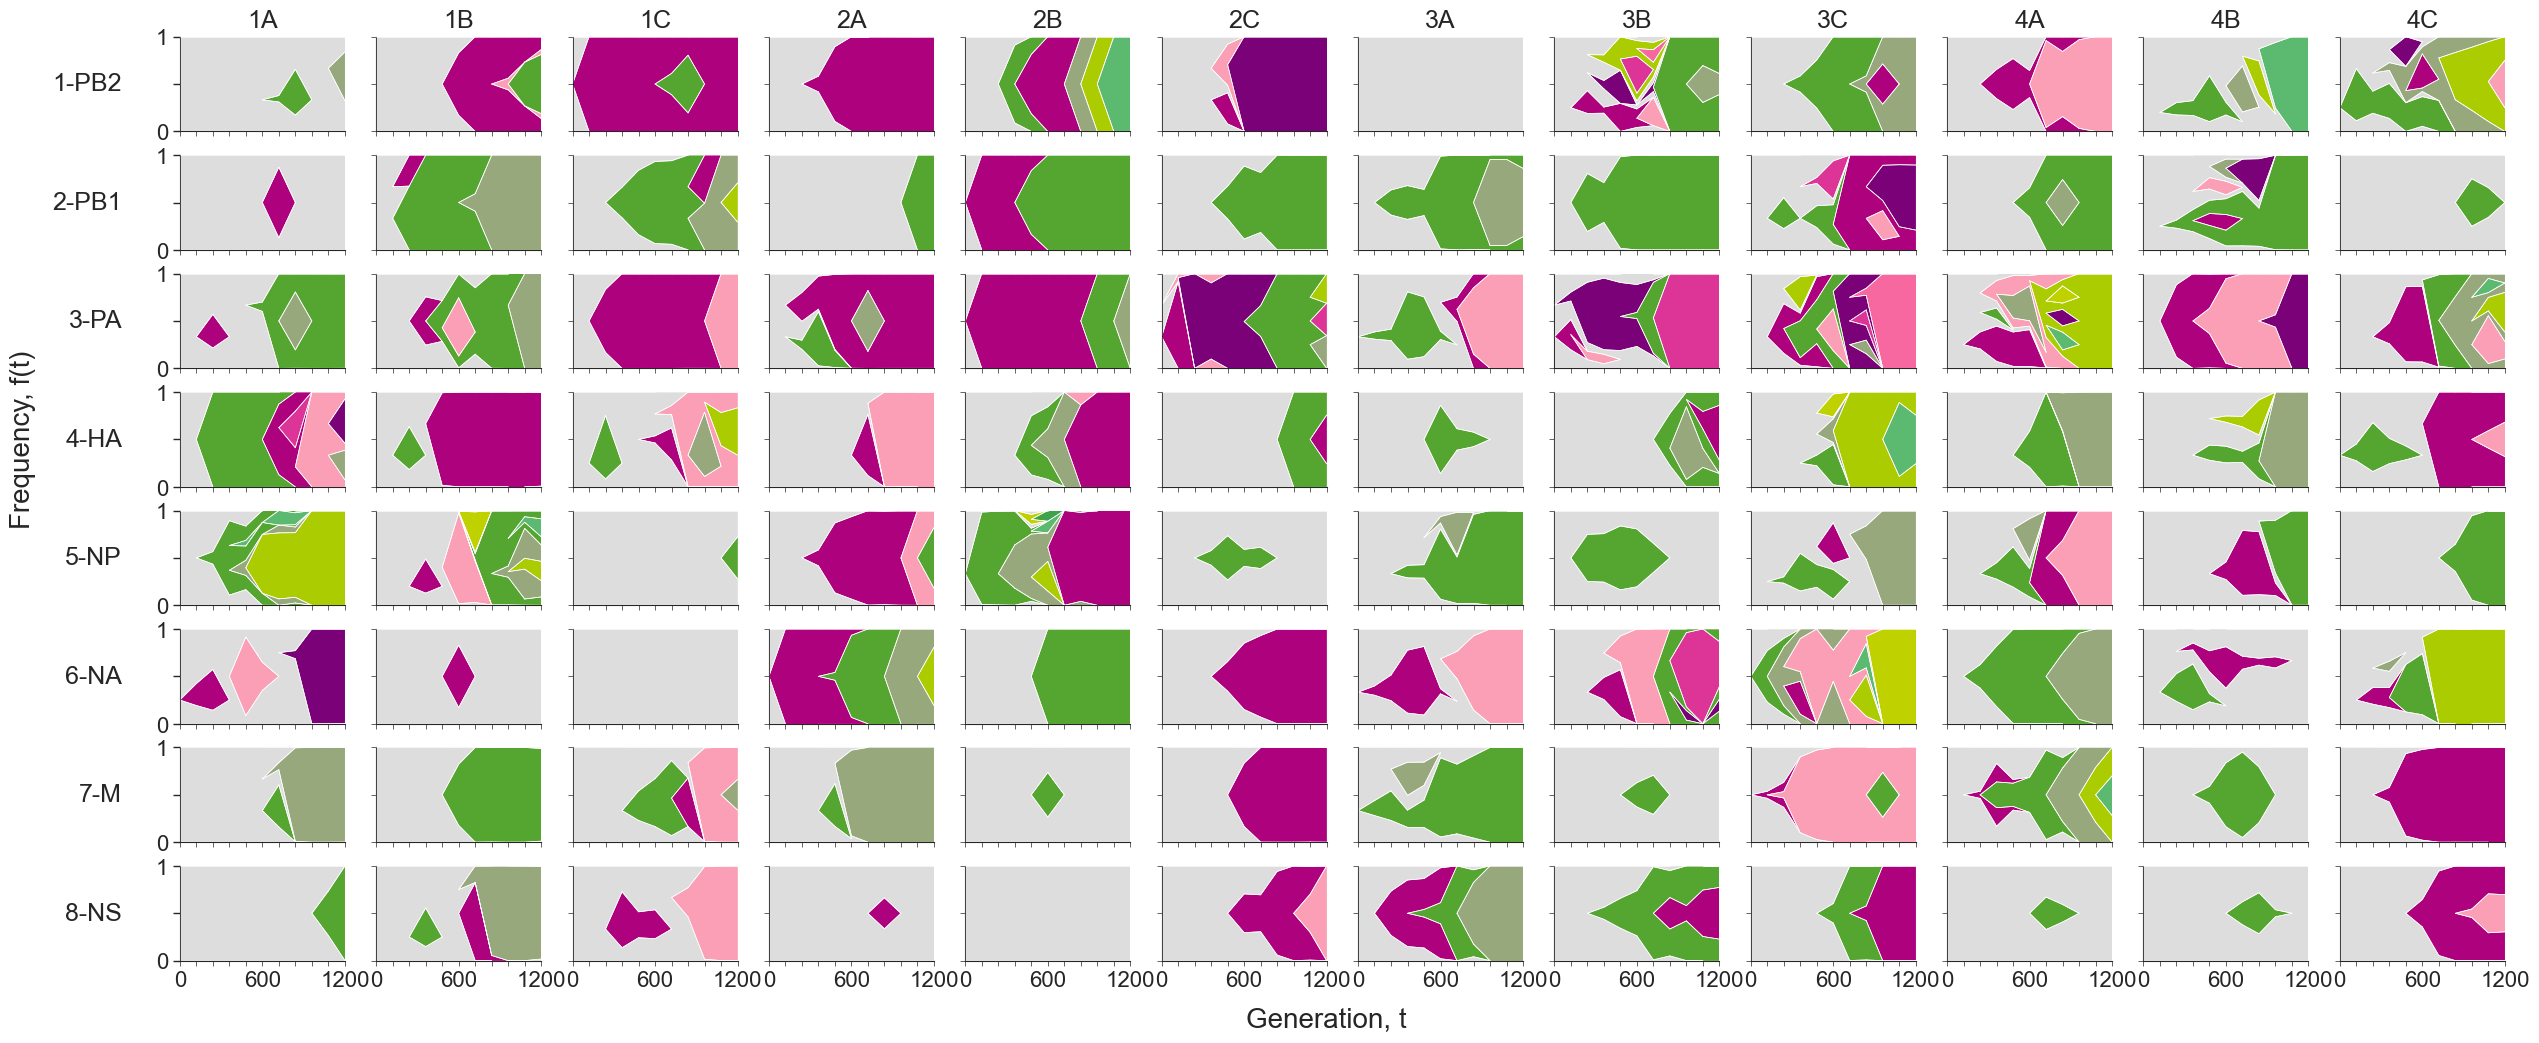

In [17]:
haplotype_detection_limit = haplotype_frequency_cutoff
haplotype_detection_limit_1 = 0.1 #each haplotype should have at least an observation of 10%
haplotype_detection_limit_2 = 0.05#plotting each observation above 5% (haplotype detection limit)

# fig = plt.figure(figsize=(30, 10))
fig = plt.figure(figsize=(30, 12))

gs = gridspec.GridSpec(1,len(populations), wspace=0.19, hspace=-0.2)

haplotype_detection_limit = haplotype_frequency_cutoff

for i, population in enumerate(populations):

    timepoints = passages
    gsi = gridspec.GridSpecFromSubplotSpec(len(segments), 1, subplot_spec=gs[i], hspace=0.25)
    
    for j, refname in enumerate(segments):
        
        ax= fig.add_subplot(gsi[j])
        haplotype_df = generate_haplotype_df(population, refname, raw_haplotypes, haplotype_detection_limit_1)

        haplotype_order = get_haplotype_order(haplotype_df, timepoints)
        
        haplotype_plotdf = generate_haplotype_plotting_df(haplotype_df, timepoints, haplotype_order, haplotype_detection_limit_2)
        
        haplotype_appearance= get_haplotype_appearance(haplotype_df)
                          
        
        p = muller_plot(ax, timepoints, haplotype_plotdf.T, haplotype_order, haplotype_appearance, alpha=1, edgecolor="white", color_seed=8, non_synonymous_dict=non_synonymous_dict[refname])
        
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, timepoints[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        
        ax.set_ylim(0,1)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_xticks(passages)

        if i != 0:
            ax.set_yticklabels([])
        else:
            ax.set_yticklabels([0, '', 1], size=16)
            #ax.set_ylabel("relative\nabundance", size=10)
            # ax.text(-40, 0.5, refname.split("-")[-1], rotation=90, va="center", size=18, fontweight="bold")
            ax.text(-35, 0.5, refname,  va="center", size=18, ha="right", )
            
            
            
        if j != len(segments)-1:
            ax.set_xticklabels([])
        else:
            #ax.set_xlabel("Generation, t")                          
            ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=16)
        if j == 0:
            ax.text(50, 1.1, population, ha="center", size=18, )
            
        if j == 7 and i == 5:
            ax.text(100, -.7, "Generation, t", ha="center", size=20,)
        if i == 0 and j == 3:
            ax.text(-95, 0.5, "Frequency, f(t)", ha="center", va="center", size=20, rotation=90)
        if i == 0:
            ax.tick_params(axis="y", size=5, width=1)

# fig.savefig("../figures/fig5_muller_plot.svg", dpi=300,bbox_inches='tight')#
fig.savefig("../figures/fig5_muller_plot.png", dpi=300,bbox_inches='tight')   

**Figure 5 Dynamics of reconstructed haplotypes of non-neutral SNVs within each population per segment.** Within each subplot, each haplotype is shown in a unique shade of either pink or green. The colour of the haplotype denotes whether the latest SNV gained within the haplotype was non-synonymous (pink) or synonymous (green). In case of multiple gained SNVs within a haplotype, the haplotype is coloured pink if one of these SNVs was non-synonymous; otherwise, it was coloured green. Only haplotype observations above 5% frequency and only haplotypes with at least one observation above 10% frequency are plotted. The grey background shade indicates the ancestral haplotype. 

### 3.1. annotated individual figures 

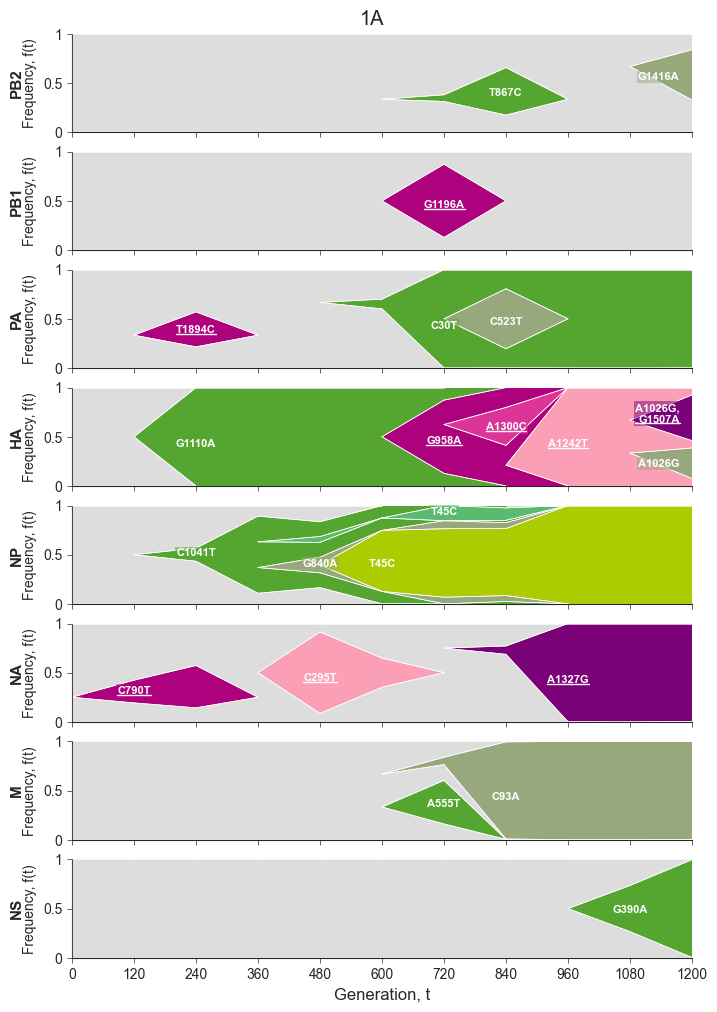

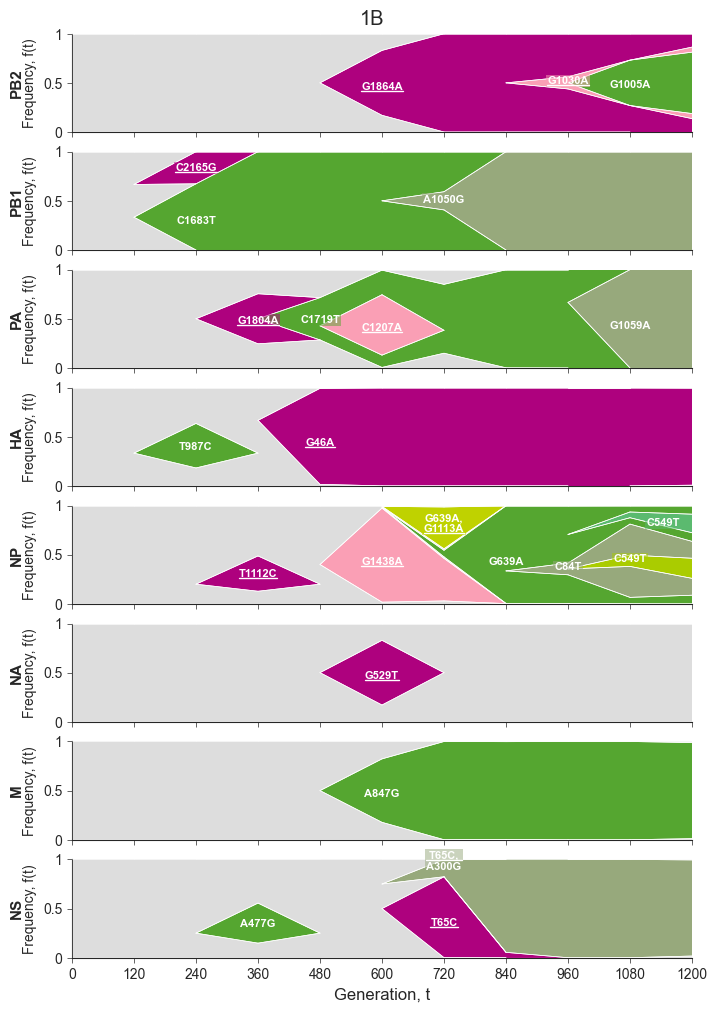

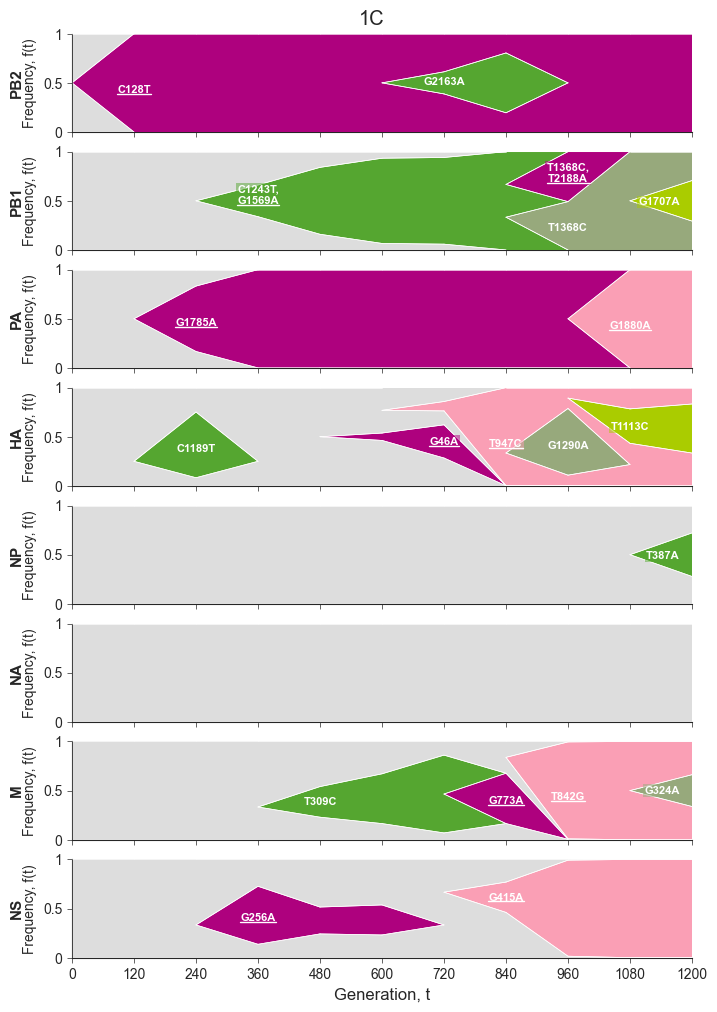

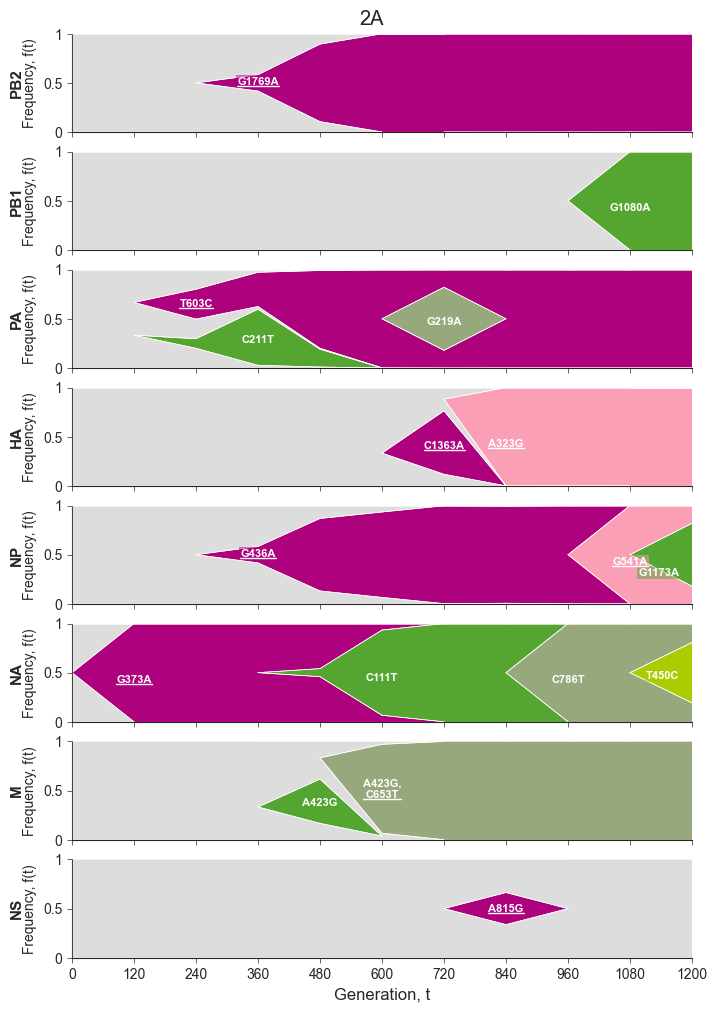

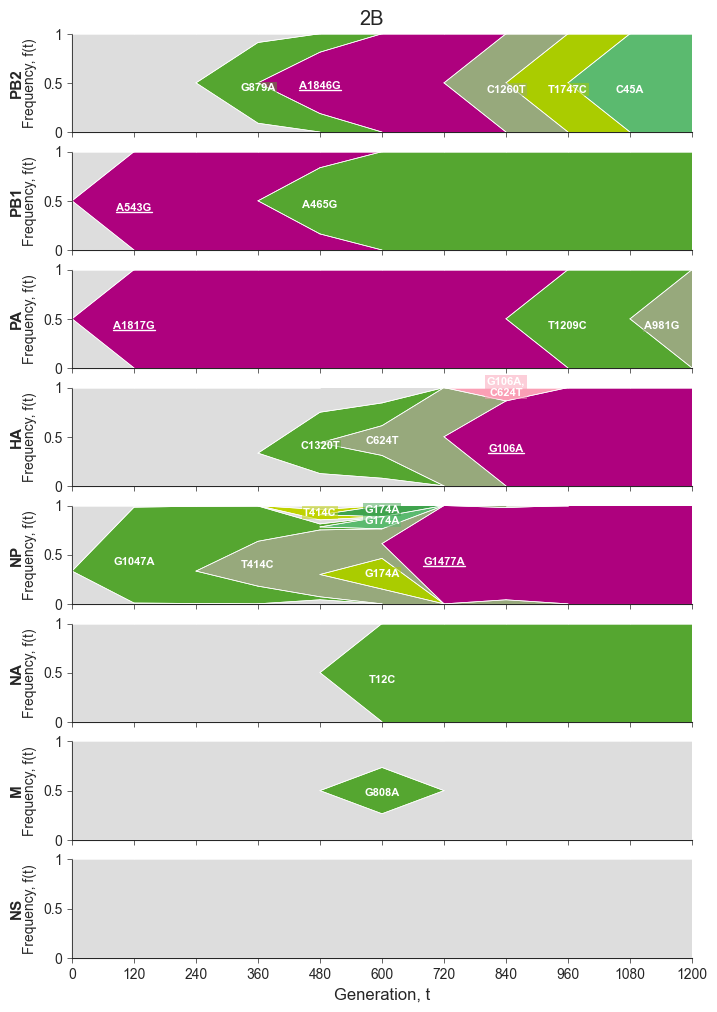

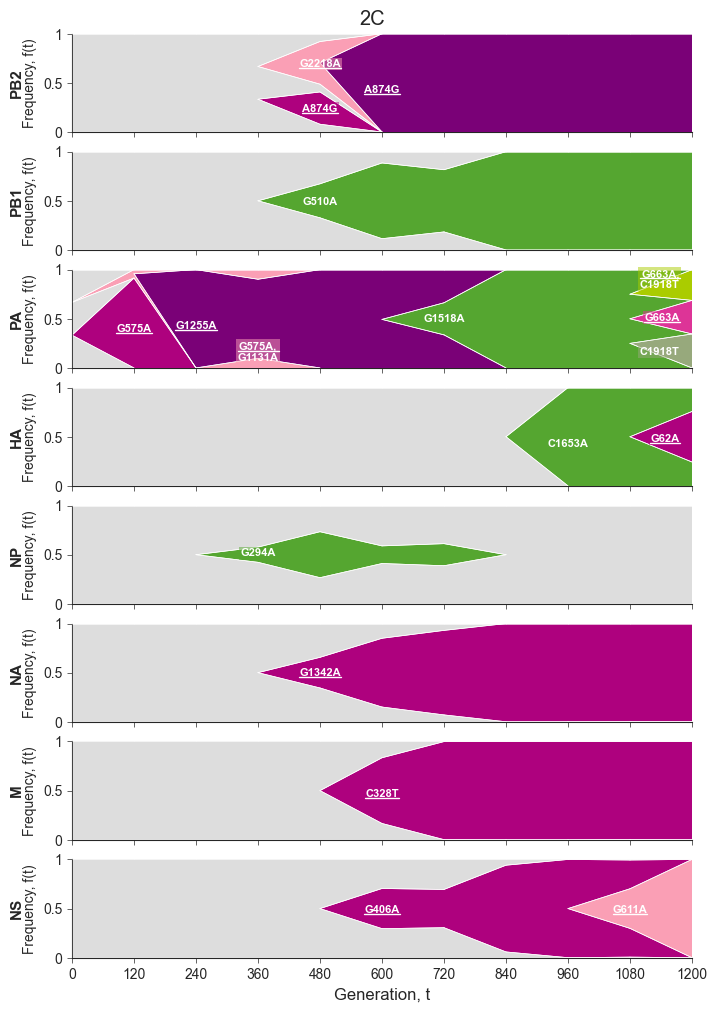

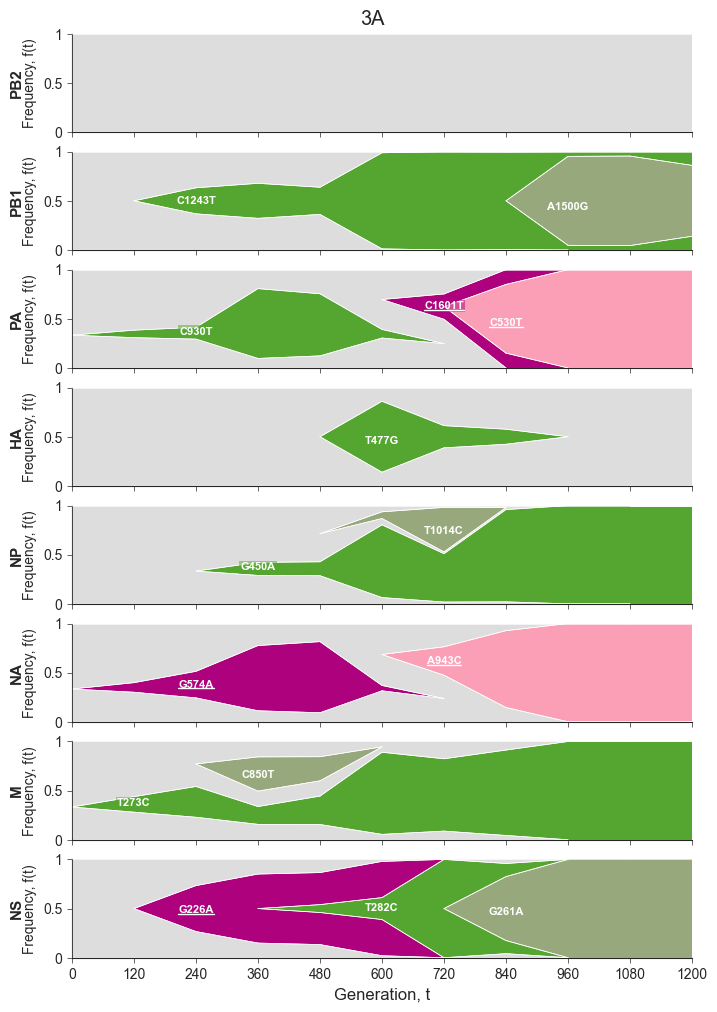

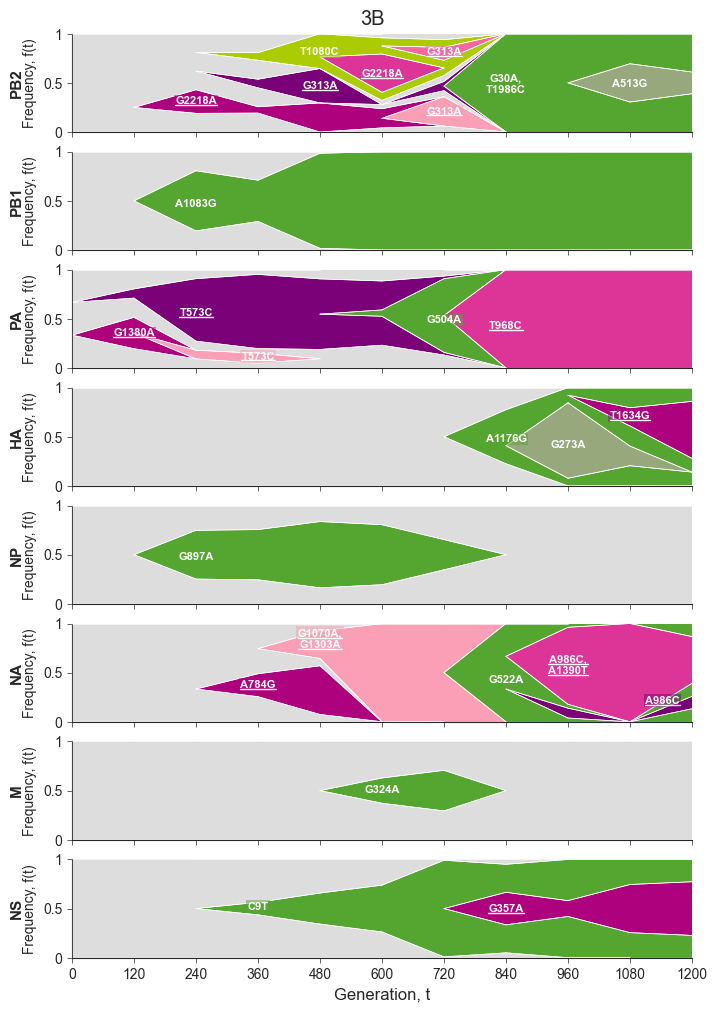

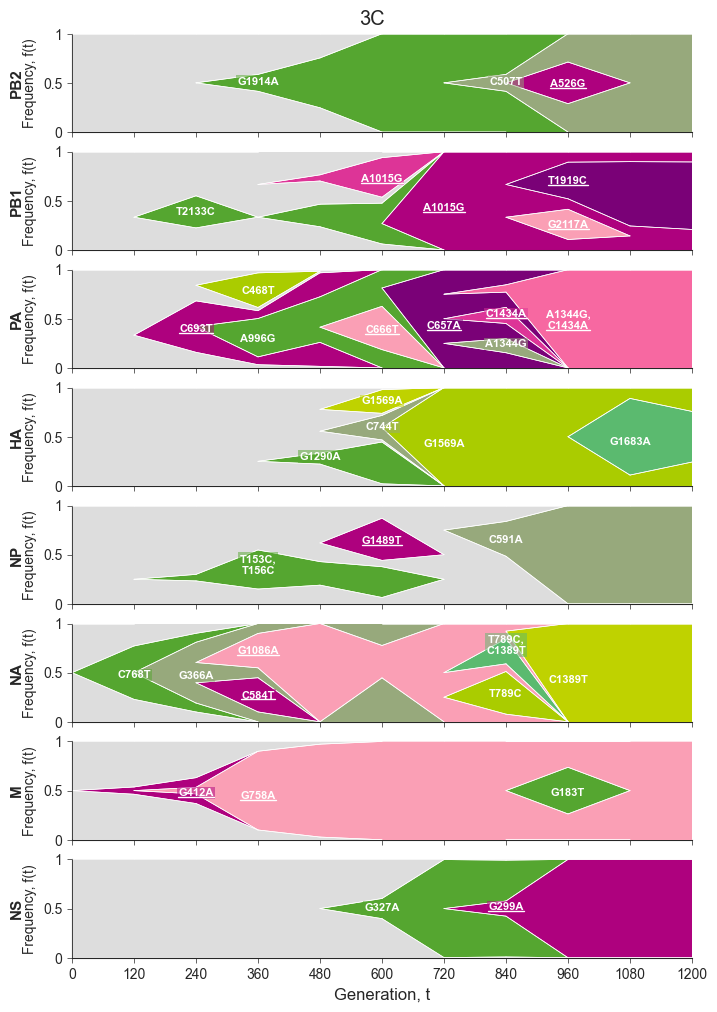

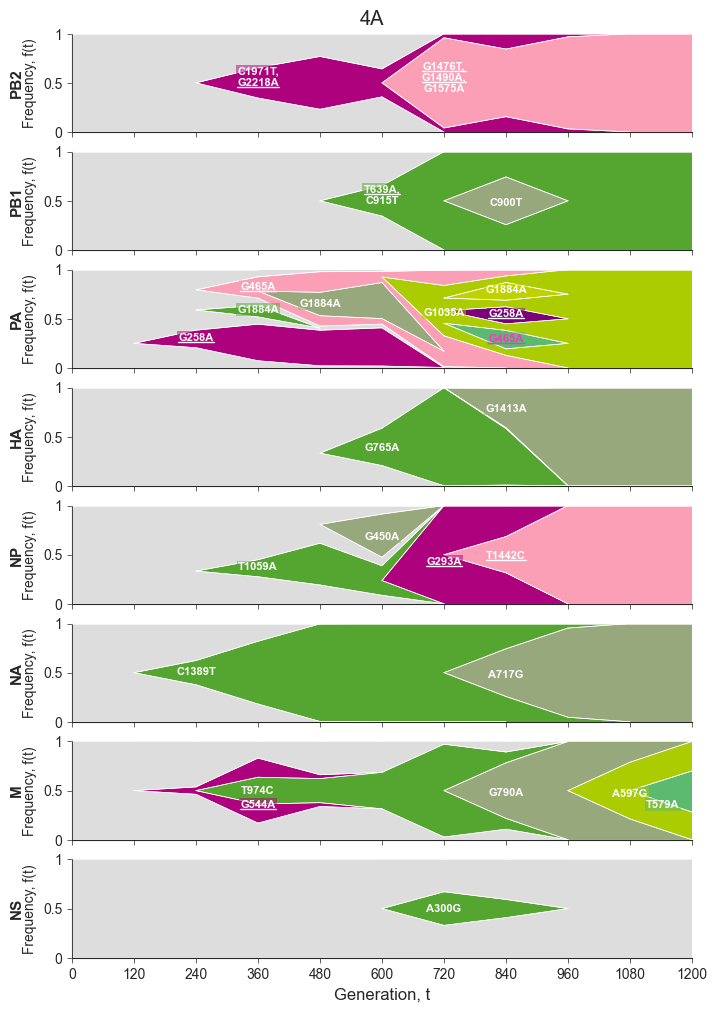

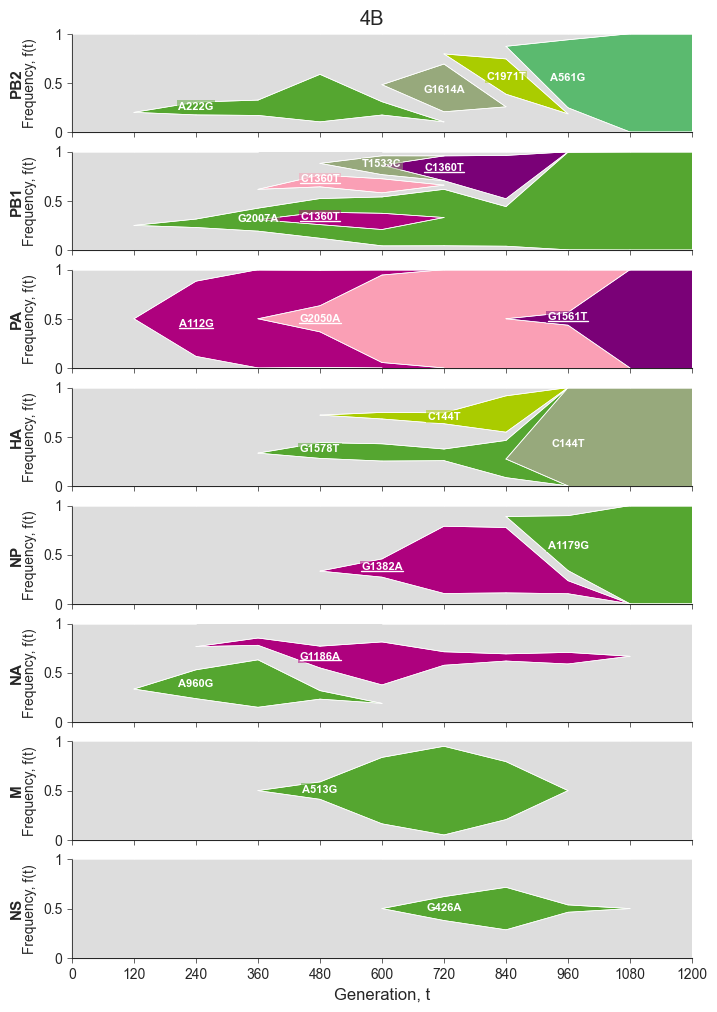

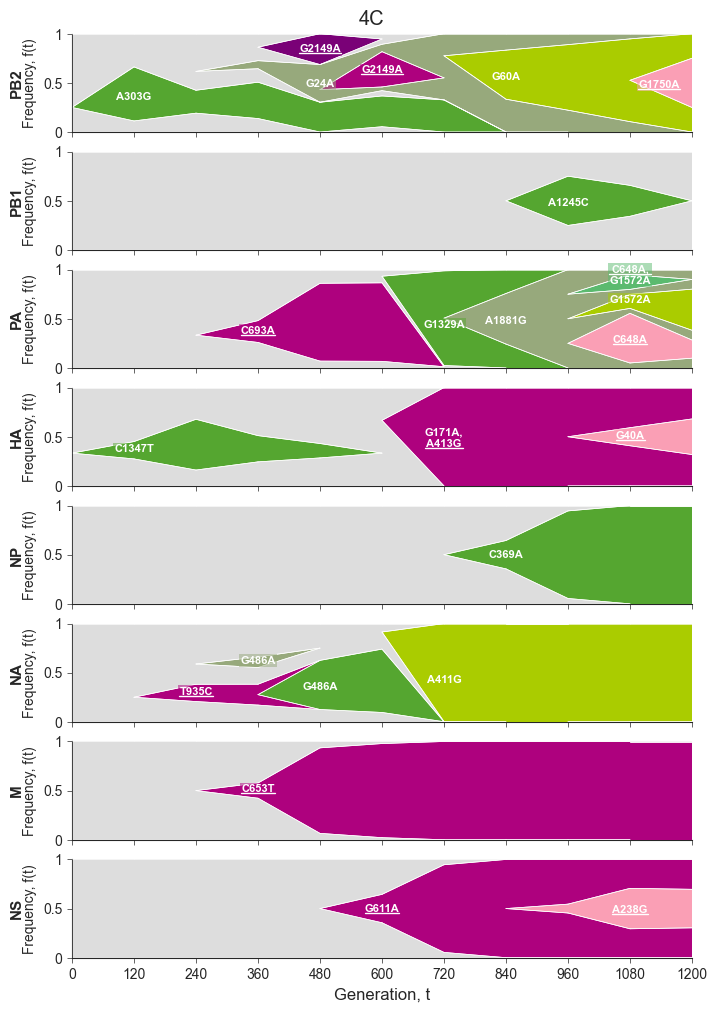

In [18]:


haplotype_detection_limit_1 = 0.1 #each haplotype should have at least an observation of 10%
haplotype_detection_limit_2 = haplotype_detection_limit #plotting each observation above 5% (haplotype detection limit)


for donor in donors:
    for replicate in replicates:
        population = f"{donor}{replicate}"
        
        fig, axes = plt.subplots(8,1, figsize=(8,12))
        
        for i, refname in enumerate(segments):
            ax =axes[i]
            try:

                haplotype_df = generate_haplotype_df(population, refname, raw_haplotypes, haplotype_detection_limit_1)
            except:
                
                fig.delaxes(ax)
                continue
            
            timepoints = passages
            haplotype_order = get_haplotype_order(haplotype_df, timepoints)
        
            
            haplotype_plotdf = generate_haplotype_plotting_df(haplotype_df, timepoints, haplotype_order, haplotype_detection_limit_2)
            
            haplotype_appearance= get_haplotype_appearance(haplotype_df)
                        
            
            p = muller_plot(ax, timepoints, haplotype_plotdf.T, haplotype_order, haplotype_appearance, alpha=1, edgecolor="white", color_seed=8, non_synonymous_dict=non_synonymous_dict[refname])
            
            muller_plot_cosmetics(ax, timepoints)
            
            color_list = generate_color_per_haplotype(haplotype_order,haplotype_appearance, seed=8,non_synonymous_dict=non_synonymous_dict[refname])
            haplotype_color_dict = {haplotype:color_list[i] for i, haplotype in enumerate(haplotype_order)}
            
            # ref_summary = snv_summary.reset_index().set_index("refname").loc[refname].set_index("snv").sort_index()
            # non_synonymous_dict = {snv:True if True in ref_summary.loc[[snv]]["non_synonymous"].values else False for snv in ref_summary.index.unique()}      

            ax.set_xlim(0, passages[-1])
            texts = annotate_muller_plot( ax, haplotype_df, haplotype_plotdf, non_synonymous_dict, haplotype_color_dict)
            resolve_text_overlaps(ax, texts, padding=0.015)
            highlight_non_synonymous_snvs(ax,texts,non_synonymous_dict[refname])

            ax.set_xticks([p for p in timepoints if p%10==0])
            if i != len(segments)-1:
                ax.set_xticklabels(["" for p in timepoints if p%10==0])
                
            ax.set_ylabel("Frequency, f(t)", size=10)
            
            ax.text(-10, 0.5, refname.split("-")[-1], rotation=90, va="center", size=11, fontweight="bold")
            
            ax.set_xticks(passages)          
            if i == len(segments)-1:
                ax.set_xlabel("Generation, t")  
                ax.set_xticklabels([int((p*hours_per_passage)/generation_time) for p in passages])          
             
            ax.set_yticks([0, 0.5, 1])
            ax.set_yticklabels([0, 0.5, 1])
            
                        
        fig.suptitle(f"{donor}{replicate}", y=0.90)
